# Robust Satellite Image Time-Series Spectral Index Extraction & Gap Imputation

In [ ]:
!pip install git+https://github.com/mistralai/timestral.git   # Python >= 3.10, torch >= 2.4


In [2]:
import ee
import geemap
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from google.colab import drive
from datetime import datetime, timedelta
from prophet import Prophet
from timestral import TimestralForecaster

EE-PROJECT = 'EE-PROJECT-NAME'

In [3]:
# Authenticate Google Earth Engine (GEE) and mount Google Drive
ee.Authenticate()
ee.Initialize(project=EE-PROJECT)
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Load the FAO GAUL Second-Level Administrative Boundaries (2015)
# We filter specifically for the Krishna district in Andhra Pradesh, India
aoi = ee.FeatureCollection('FAO/GAUL_SIMPLIFIED_500m/2025/level2') \
    .filter(ee.Filter.eq('GAUL2_NAME', 'Krishna'))

# Initialize and display the interactive map centered on Krishna district
map_viewer = geemap.Map()
map_viewer.add_basemap('HYBRID')
map_viewer.centerObject(aoi, 9)
map_viewer.addLayer(aoi, {}, 'Krishna District Boundary')
map_viewer

Map(center=[16.555422125630454, 80.79837982438772], controls=(WidgetControl(options=['position', 'transparent_…

In [18]:
# =========================================================================
# 1. LOAD CROPLAND DATASETS TO BUILD CONSENSUS (WITHOUT FORCE-REPROJECTION)
# =========================================================================

# Source A: ESRI 10m Land Use Land Cover (Year 2021) - Crop value is 5
esri_lc = ee.ImageCollection('projects/sat-io/open-datasets/landcover/ESRI_Global-LULC_10m_TS') \
    .filterBounds(aoi) \
    .filter(ee.Filter.calendarRange(2021, 2021, 'year')) \
    .mosaic() \
    .clip(aoi)
esri_crop_mask = esri_lc.eq(5)

# Source B: ESA WorldCover v200 (10m) - Cropland value is 40
esa_lc = ee.ImageCollection('ESA/WorldCover/v200') \
    .filterBounds(aoi) \
    .select('Map') \
    .mosaic() \
    .clip(aoi)
esa_crop_mask = esa_lc.eq(40)

# Source C: Copernicus Global Land Cover (100m, Year 2019) - Cropland value is 40
copernicus_lc = ee.ImageCollection('COPERNICUS/Landcover/100m/Proba-V-C3/Global') \
    .filterDate('2019-01-01', '2019-12-31') \
    .first() \
    .select('discrete_classification') \
    .clip(aoi)
copernicus_crop_mask = copernicus_lc.eq(40)

# Source D: FROM-GLC10 (10m) - Cropland value is 10
from_glc_lc = ee.ImageCollection('projects/sat-io/open-datasets/FROM-GLC10') \
    .filterBounds(aoi) \
    .mosaic() \
    .clip(aoi)
from_glc_crop_mask = from_glc_lc.eq(10)

# Source E: GLC-FCS30D Annual Land Cover - Cropland range codes: 10 to 20
glc_fcs_lc = ee.ImageCollection('projects/sat-io/open-datasets/GLC-FCS30D/annual') \
    .filterBounds(aoi) \
    .mosaic() \
    .select('b22') \
    .clip(aoi)
glc_fcs_crop_mask = glc_fcs_lc.gte(10).And(glc_fcs_lc.lte(20))

# =========================================================================
# 2. CALCULATE PIXEL AGREEMENT SUM AND GENERATE CONSENSUS MASK
# =========================================================================

# Combine all crop masks (allowing dynamic resolution scaling during compilation)
crop_masks_collection = ee.ImageCollection.fromImages([
    esri_crop_mask.rename('mask').toByte(),
    esa_crop_mask.rename('mask').toByte(),
    copernicus_crop_mask.rename('mask').toByte(),
    from_glc_crop_mask.rename('mask').toByte(),
    glc_fcs_crop_mask.rename('mask').toByte()
])

# Compute total layer agreement (values 0 to 5)
agreement_pixel_sum = crop_masks_collection.sum()

# Define Class Labels:
# 2 = All 5 datasets agree on Cropland
# 1 = All 5 datasets agree on Non-Cropland
# 0 = Disagreement among datasets
consensus_cropmask = ee.Image(0) \
    .where(agreement_pixel_sum.eq(0), 1) \
    .where(agreement_pixel_sum.eq(5), 2) \
    .rename('consensus') \
    .toByte() \
    .clip(aoi)

# Visualization Palette: Disagreement (yellow), Non-crop (lightgray), Cropland (green)
vis_parameters = {
    'min': 0,
    'max': 2,
    'palette': ['yellow', 'lightgray', 'green']
}

map_viewer.addLayer(consensus_cropmask, vis_parameters, 'Cropland Consensus Mask')
map_viewer

Map(bottom=59723.0, center=[16.555422125630454, 80.79837982438772], controls=(WidgetControl(options=['position…

In [6]:
# Define the target study period (Kharif crop windows: mid-July to December 2021)
start_date_str = '2021-07-15'
end_date_str = '2022-01-01'
temporal_step_days = 15

start_dt = datetime.strptime(start_date_str, '%Y-%m-%d')
end_dt = datetime.strptime(end_date_str, '%Y-%m-%d')

# Generate sequential 15-day time intervals for NDVI compositing
window_intervals = []
window_idx = 0

while start_dt < end_dt:
    current_window_end = start_dt + timedelta(days=temporal_step_days)
    if current_window_end > end_dt:
        current_window_end = end_dt

    # Calculate the midpoint date for plotting labels
    midpoint_label = (start_dt + timedelta(days=temporal_step_days // 2)).strftime('%Y-%m-%d')

    window_intervals.append((
        start_dt.strftime('%Y-%m-%d'),
        current_window_end.strftime('%Y-%m-%d'),
        window_idx + 1,
        midpoint_label
    ))

    start_dt = current_window_end
    window_idx += 1

# Drop the last incomplete period to keep exact intervals
window_intervals = window_intervals[:-1]
print(f"Generated {len(window_intervals)} temporal windows:")
print(window_intervals)

Generated 11 temporal windows:
[('2021-07-15', '2021-07-30', 1, '2021-07-22'), ('2021-07-30', '2021-08-14', 2, '2021-08-06'), ('2021-08-14', '2021-08-29', 3, '2021-08-21'), ('2021-08-29', '2021-09-13', 4, '2021-09-05'), ('2021-09-13', '2021-09-28', 5, '2021-09-20'), ('2021-09-28', '2021-10-13', 6, '2021-10-05'), ('2021-10-13', '2021-10-28', 7, '2021-10-20'), ('2021-10-28', '2021-11-12', 8, '2021-11-04'), ('2021-11-12', '2021-11-27', 9, '2021-11-19'), ('2021-11-27', '2021-12-12', 10, '2021-12-04'), ('2021-12-12', '2021-12-27', 11, '2021-12-19')]


In [12]:
#=============================================================================
# Sentinel-2 preprocessing: cloud/shadow masking, scaling, and resampling
#=============================================================================
def preprocess_s2(image):
    # 1. Mask clouds and cirrus using the QA60 band
    qa60 = image.select('QA60')
    cloud_bit = 1 << 10
    cirrus_bit = 1 << 11
    qa60_mask = (qa60.bitwiseAnd(cloud_bit).eq(0).And(qa60.bitwiseAnd(cirrus_bit).eq(0)))

    # 2. Drop SCL classes: 3=cloud shadow, 8/9=cloud prob, 10=thin cirrus
    scl = image.select('SCL')
    scl_mask = (scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)))

    # 3. Filter clear skies (cs >= 0.5) using Cloud Score+
    cs_mask = image.select('cs').gte(0.5)
    final_mask = qa60_mask.And(scl_mask).And(cs_mask)

    # 4. Scale reflectance to [0, 1] range; retain cs band raw scale
    spectral = image.select(['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B11', 'B12']).divide(10000)
    quality = image.select(['cs'])
    masked = ee.Image(spectral.addBands(quality).updateMask(final_mask).copyProperties(image, ['system:time_start']))

    # 5. Resample 20m spatial resolution bands to match the 10m bands
    bands_10m = masked.select(['B2', 'B3', 'B4', 'B8'])
    bands_20m = masked.select(['B5', 'B6', 'B7', 'B11', 'B12']).resample('bilinear')
    quality = masked.select(['cs'])
    return bands_10m.addBands(bands_20m).addBands(quality)

In [8]:
# Global parameters for Sentinel-2 bands
S2_BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B11', 'B12']
CS_QUALITY_BAND = 'cs'

def make_empty_composite():
    # Returns an empty image filled with 0s as a fallback when no images exist in a time step
    fallback_bands = [ee.Image.constant(0).rename(band_name).updateMask(ee.Image.constant(0)) for band_name in S2_BANDS]
    return ee.Image.cat(fallback_bands).toFloat()

def generate_cloud_free_composite(period_metadata):
    # Extract window metadata
    win_start, win_end, _, time_label = period_metadata

    # Filter the preprocessed image collection to our target temporal window
    window_collection = sentinel_collection.filterDate(win_start, win_end)

    # Quality-mosaic chooses the clearest pixel based on highest Cloud Score+ ('cs')
    def build_mosaic():
        selected_subset = window_collection.select(S2_BANDS + [CS_QUALITY_BAND])
        return selected_subset.qualityMosaic(CS_QUALITY_BAND).select(S2_BANDS).toFloat()

    # Apply fallback algorithm if image collection is empty for this time step
    composite_image = ee.Image(
        ee.Algorithms.If(
            window_collection.size().gt(0),
            build_mosaic(),
            make_empty_composite()
        )
    )

    return composite_image.set({
        'label': time_label,
        'window_start': win_start,
        'window_end': win_end
    })

In [13]:
# Load Cloud Score+ quality bands collection
cs_plus = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")

# Initialize, filter, and preprocess Sentinel-2 Surface Reflectance collection
s2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(aoi)
    .filterDate(start_date_str, end_date_str)
    .linkCollection(cs_plus, [CS_QUALITY_BAND])
    .map(lambda element: preprocess_s2(ee.Image(element)))
)

# Point our main reference pointer to the structured collection
sentinel_collection = s2

print("Sentinel-2 collection initialized with size:", s2.size().getInfo())

Sentinel-2 collection initialized with size: 299


In [14]:
# Build sequential 15-day cloud-free composite list
sentinel_raw_composites = [generate_cloud_free_composite(p) for p in window_intervals]

In [15]:
# Sanity check composite outputs
print(f"Generated total composites: {len(sentinel_raw_composites)}")
if len(sentinel_raw_composites) > 0:
    first_metadata = sentinel_raw_composites[0].getInfo()
    print("\n--- First Composite Profile ---")
    print("Available Bands:", [band_desc['id'] for band_name, band_desc in zip(first_metadata['bands'], first_metadata['bands'])])
    print("Properties:", first_metadata['properties'])

Generated total composites: 11

--- First Composite Profile ---
Available Bands: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B11', 'B12']
Properties: {'window_end': '2021-07-30', 'window_start': '2021-07-15', 'label': '2021-07-22'}


In [19]:
# Extracts regional mean NDVI over agreed cropland pixels
def extract_cropland_mean_ndvi(image):
    # Calculate standardized NDVI
    ndvi_layer = image.normalizedDifference(['B8', 'B4']).rename('NDVI')

    # Mask image so we only retain pixels where all datasets agree on cropland (class 2)
    cropland_only_ndvi = ndvi_layer.updateMask(consensus_cropmask.eq(2))

    # Reduce the region to compute a single representative mean value
    # We increase the scale to 500 meters to resolve the 'Reprojection output too large' memory issue
    regional_mean = cropland_only_ndvi.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi.geometry(),
        scale=100,
        maxPixels=1e9
    )

    return ee.Feature(None, {
        'ndvi': regional_mean.get('NDVI'),
        'date': image.get('label')
    })

# Map calculation over the composite image series
ndvi_results = ee.FeatureCollection([extract_cropland_mean_ndvi(img) for img in sentinel_raw_composites]).getInfo()

# Extract into easy-to-use lists
dates = []
ndvi_vals = []

for feature in ndvi_results['features']:
    attributes = feature['properties']
    dates.append(attributes['date'])
    ndvi_vals.append(attributes['ndvi'] if attributes['ndvi'] is not None else np.nan)

print("Extracted Time-Series:")
print("Dates:", dates)
print("NDVI:", ndvi_vals)

Extracted Time-Series:
Dates: ['2021-07-22', '2021-08-06', '2021-08-21', '2021-09-05', '2021-09-20', '2021-10-05', '2021-10-20', '2021-11-04', '2021-11-19', '2021-12-04', '2021-12-19']
NDVI: [0.2569484510427989, 0.3607180494437356, 0.525195631370554, 0.5888000142463763, 0.6469904111259502, 0.7031929848326302, 0.7169958432999339, 0.579565724714248, 0.6471589644066403, 0.5544699321496473, 0.4445865437027517]


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

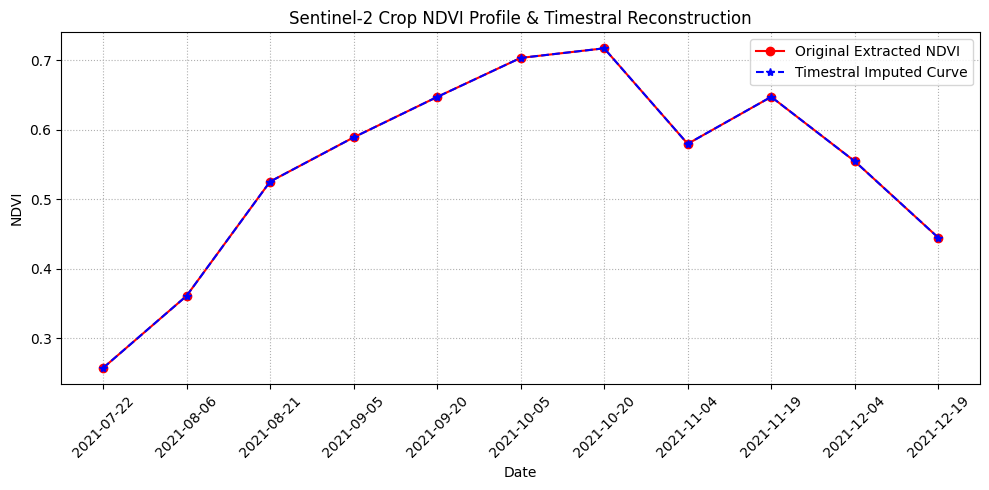

In [20]:
# Convert NDVI values to array
ndvi_numerical_array = np.array(ndvi_vals)

# Set up context tensor for Timestral Model evaluation (batch, sequence, features)
context_data_tensor = torch.tensor(np.nan_to_num(ndvi_numerical_array, nan=0.0), dtype=torch.float32).unsqueeze(0).unsqueeze(-1)

# Load pre-trained foundation forecasting model
timestral_model = TimestralForecaster.from_pretrained(
    "mistralai/Timestral-209M",
    device="cuda" if torch.cuda.is_available() else "cpu"
)

with torch.no_grad():
    # Forecast future sequence values
    predictions_output = timestral_model.forecast(context_data_tensor, prediction_length=len(ndvi_vals))
    imputed_predictions = predictions_output.median[0, :, 0].cpu().numpy()

# Create filled time series (gaps replaced with Timestral's predictions)
timestral_filled_ndvi = [orig if not np.isnan(orig) else pred for orig, pred in zip(ndvi_vals, imputed_predictions)]

# Plot actual vs imputed profiles
plt.figure(figsize=(10, 5))
plt.plot(dates, ndvi_vals, 'ro-', label='Original Extracted NDVI')
plt.plot(dates, timestral_filled_ndvi, 'b*--', label='Timestral Imputed Curve')
plt.title('Sentinel-2 Crop NDVI Profile & Timestral Reconstruction')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.xticks(rotation=45)
plt.grid(True, linestyle=':')
plt.legend()
plt.tight_layout()
plt.show()

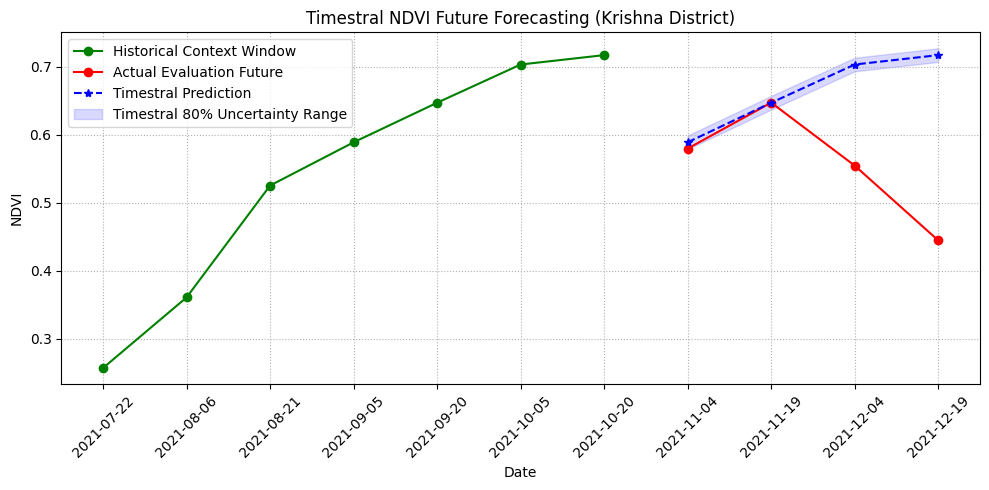

In [21]:
# Configure a train-test temporal split
# Input context represents first 7 points (2021-07-22 to 2021-10-20)
context_dates = dates[:7]
context_ndvi = ndvi_vals[:7]

# Evaluation target represents last 4 points
forecast_dates = dates[7:]
actual_forecast_ndvi = ndvi_vals[7:]

# Build PyTorch context tensor
training_context_tensor = torch.tensor(context_ndvi, dtype=torch.float32).unsqueeze(0).unsqueeze(-1)
prediction_horizon = len(forecast_dates)

with torch.no_grad():
    # Execute Timestral forward pass on context window
    model_output = timestral_model.forecast(training_context_tensor, prediction_length=prediction_horizon)

    # Extract prediction intervals
    full_predictions = model_output.median[0, :, 0].cpu().numpy()
    timestral_predictions = full_predictions[-prediction_horizon:]

    full_lower = model_output.quantile(0.1)[0, :, 0].cpu().numpy()
    timestral_lower_bound = full_lower[-prediction_horizon:]

    full_upper = model_output.quantile(0.9)[0, :, 0].cpu().numpy()
    timestral_upper_bound = full_upper[-prediction_horizon:]

# Plot forecast comparison with confidence intervals
plt.figure(figsize=(10, 5))
plt.plot(context_dates, context_ndvi, 'go-', label='Historical Context Window')
plt.plot(forecast_dates, actual_forecast_ndvi, 'ro-', label='Actual Evaluation Future')
plt.plot(forecast_dates, timestral_predictions, 'b*--', label='Timestral Prediction')
plt.fill_between(forecast_dates, timestral_lower_bound, timestral_upper_bound, color='blue', alpha=0.15, label='Timestral 80% Uncertainty Range')

plt.title('Timestral NDVI Future Forecasting (Krishna District)')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.xticks(rotation=45)
plt.grid(True, linestyle=':')
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
# Re-format the training slice to Prophet's expected dataframe configuration
prophet_df = pd.DataFrame({
    'ds': pd.to_datetime(context_dates),
    'y': context_ndvi
})

# Initialize and train Prophet
prophet_model = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.80
)
prophet_model.fit(prophet_df)

# Forecast both context and target evaluation horizon
prophet_future_dates = pd.DataFrame({'ds': pd.to_datetime(dates)})
prophet_forecast_results = prophet_model.predict(prophet_future_dates)

# Slice out only the forecasted future timeframe steps
future_prophet_predictions = prophet_forecast_results.iloc[7:]
prophet_forecast_yhat = future_prophet_predictions['yhat'].values
prophet_forecast_lower = future_prophet_predictions['yhat_lower'].values
prophet_forecast_upper = future_prophet_predictions['yhat_upper'].values

INFO:prophet:n_changepoints greater than number of observations. Using 4.


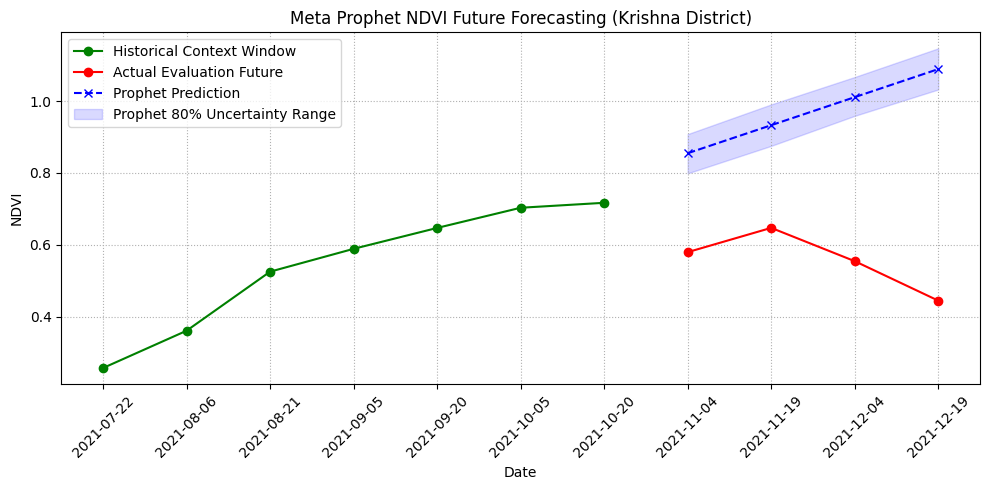

In [23]:
# Plot comparison of Prophet predictions
plt.figure(figsize=(10, 5))
plt.plot(context_dates, context_ndvi, 'go-', label='Historical Context Window')
plt.plot(forecast_dates, actual_forecast_ndvi, 'ro-', label='Actual Evaluation Future')
plt.plot(forecast_dates, prophet_forecast_yhat, 'bx--', label='Prophet Prediction')
plt.fill_between(forecast_dates, prophet_forecast_lower, prophet_forecast_upper, color='blue', alpha=0.15, label='Prophet 80% Uncertainty Range')

plt.title('Meta Prophet NDVI Future Forecasting (Krishna District)')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.xticks(rotation=45)
plt.grid(True, linestyle=':')
plt.legend()
plt.tight_layout()
plt.show()

Target Value (True NDVI): 0.5796
Linear Interpolation Point: 0.6821 (Error: 0.1025)
Cubic Spline Interpolation: 0.6997 (Error: 0.1201)


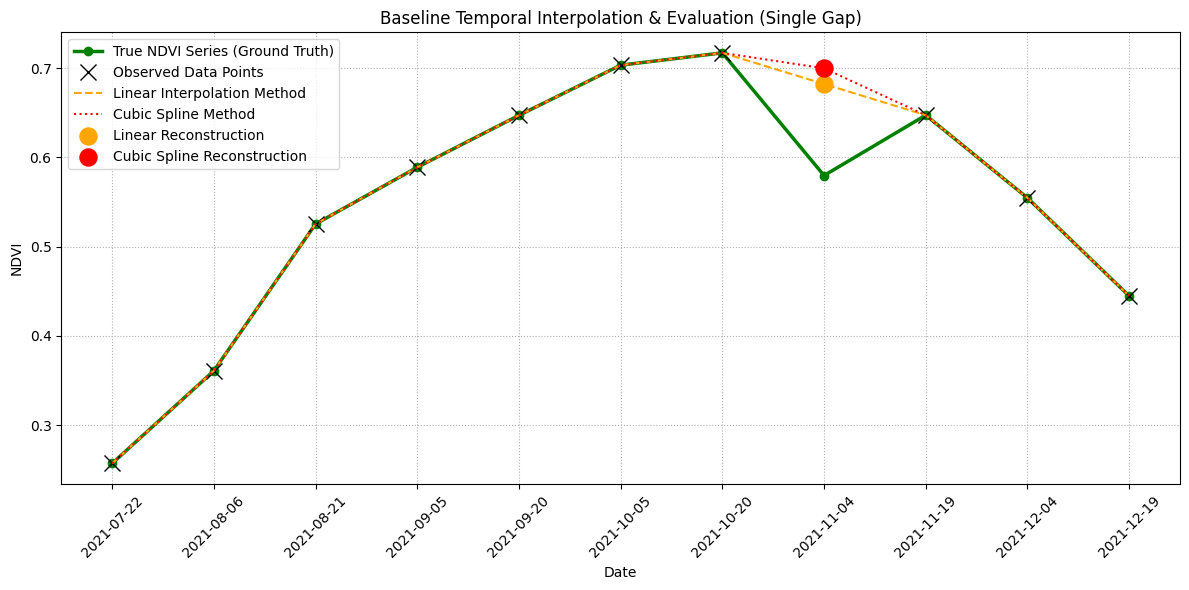

In [24]:
# Prepare the single missing gap evaluation dataset
true_time_series = np.array(ndvi_vals).copy()

# Simulating cloud/gap contamination: setting the 8th point (index 7) as missing (NaN)
single_gap_series = true_time_series.copy()
single_gap_series[7] = np.nan

# Build a temporal Pandas Series
temporal_series = pd.Series(single_gap_series, index=pd.to_datetime(dates))

# Interpolate using standard linear and cubic spline methods
linear_interpolated_series = temporal_series.interpolate(method='linear')
spline_interpolated_series = temporal_series.interpolate(method='cubic')

# Capture reconstructed results for evaluation
actual_val_index_7 = true_time_series[7]
linear_est_index_7 = linear_interpolated_series.iloc[7]
spline_est_index_7 = spline_interpolated_series.iloc[7]

print(f"Target Value (True NDVI): {actual_val_index_7:.4f}")
print(f"Linear Interpolation Point: {linear_est_index_7:.4f} (Error: {abs(linear_est_index_7 - actual_val_index_7):.4f})")
print(f"Cubic Spline Interpolation: {spline_est_index_7:.4f} (Error: {abs(spline_est_index_7 - actual_val_index_7):.4f})")

# Plot classical interpolation algorithms side-by-side
plt.figure(figsize=(12, 6))
plt.plot(dates, true_time_series, 'o-', color='green', label='True NDVI Series (Ground Truth)', linewidth=2.5)
plt.plot(dates, single_gap_series, 'kx', markersize=12, label='Observed Data Points')
plt.plot(dates, linear_interpolated_series, '--', color='orange', label='Linear Interpolation Method')
plt.plot(dates, spline_interpolated_series, ':', color='red', label='Cubic Spline Method')

# Highlight target interpolated points
plt.scatter([dates[7]], [linear_est_index_7], color='orange', s=150, zorder=5, label='Linear Reconstruction')
plt.scatter([dates[7]], [spline_est_index_7], color='red', s=150, zorder=5, label='Cubic Spline Reconstruction')

plt.title('Baseline Temporal Interpolation & Evaluation (Single Gap)')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.xticks(rotation=45)
plt.grid(True, linestyle=':')
plt.legend()
plt.tight_layout()
plt.show()

Optimizing Bidirectional Neural Imputation weights...
Epoch [50/300], Mean Squared Loss: 0.005337
Epoch [100/300], Mean Squared Loss: 0.000364
Epoch [150/300], Mean Squared Loss: 0.000144
Epoch [200/300], Mean Squared Loss: 0.000118
Epoch [250/300], Mean Squared Loss: 0.000107
Epoch [300/300], Mean Squared Loss: 0.000096

Ground Truth NDVI Value: 0.5796
Bi-LSTM Reconstruction Value: 0.6171 (Error: 0.0375)


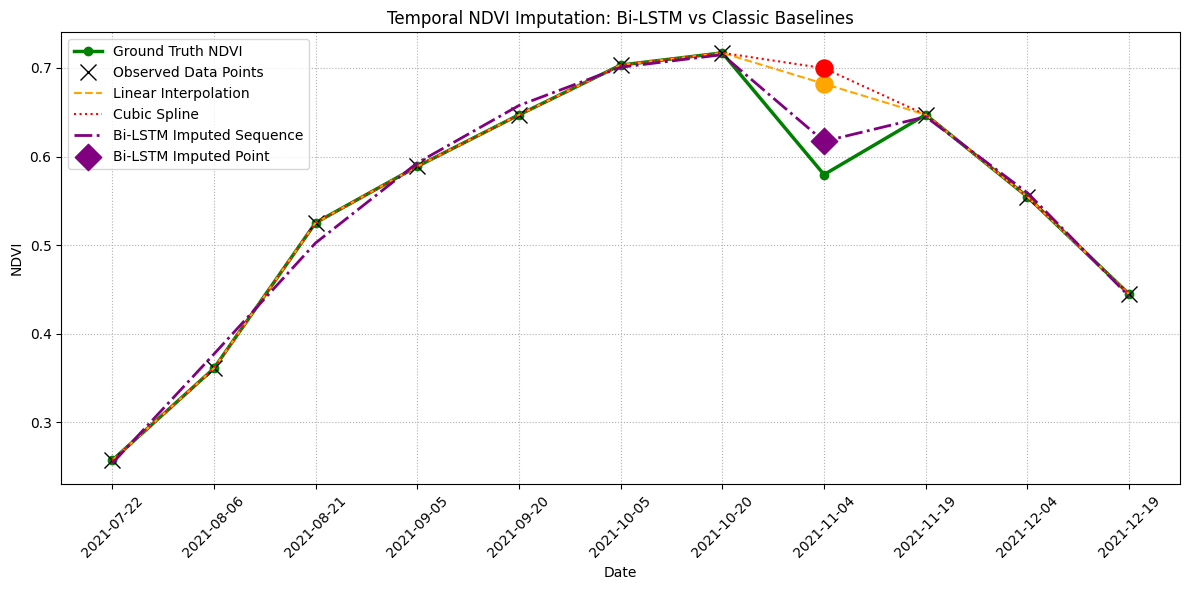

In [25]:
# =========================================================================
# BIDIRECTIONAL LSTM DEEP LEARNING FOR TIME-SERIES GAP IMPUTATION
# =========================================================================
class BiLSTMTemporalImputer(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=16, num_layers=1):
        super(BiLSTMTemporalImputer, self).__init__()
        # Use bidirectional=True to look back and forth in time simultaneously
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )
        self.projection_layer = nn.Linear(hidden_dim * 2, input_dim)

    def forward(self, sequence):
        lstm_out, _ = self.lstm(sequence)
        reconstructed_out = self.projection_layer(lstm_out)
        return reconstructed_out

# Build gappy sequence (input uses 0.0 value as placeholder representation at index 7)
x_ground_truth = np.array(ndvi_vals, dtype=np.float32)
x_gappy_mask = x_ground_truth.copy()
x_gappy_mask[7] = 0.0

# Shape datasets for neural net: [batch=1, sequence=11, features=1]
tensor_ground_truth = torch.tensor(x_ground_truth).view(1, -1, 1)
tensor_gappy_input = torch.tensor(x_gappy_mask).view(1, -1, 1)

# Initialize training variables
imputer_model = BiLSTMTemporalImputer()
training_loss_function = nn.MSELoss()
training_optimizer = optim.Adam(imputer_model.parameters(), lr=0.01)

# Compute loss only on known observation steps (ignoring index 7 target)
known_steps_mask = torch.ones_like(tensor_ground_truth, dtype=torch.bool)
known_steps_mask[0, 7, 0] = False

print("Optimizing Bidirectional Neural Imputation weights...")
imputer_model.train()
for step_epoch in range(300):
    training_optimizer.zero_grad()
    reconstructed_preds = imputer_model(tensor_gappy_input)

    # Calculate loss specifically on known values
    step_loss = training_loss_function(reconstructed_preds[known_steps_mask], tensor_ground_truth[known_steps_mask])
    step_loss.backward()
    training_optimizer.step()

    if (step_epoch + 1) % 50 == 0:
        print(f"Epoch [{step_epoch+1}/300], Mean Squared Loss: {step_loss.item():.6f}")

# Run model evaluation
imputer_model.eval()
with torch.no_grad():
    reconstructed_output = imputer_model(tensor_gappy_input)
    bilstm_reconstructed_series = reconstructed_output.squeeze().numpy()

# Fetch predicted output at masked index
bilstm_pred_index_7 = bilstm_reconstructed_series[7]
true_ground_truth_index_7 = x_ground_truth[7]

print(f"\nGround Truth NDVI Value: {true_ground_truth_index_7:.4f}")
print(f"Bi-LSTM Reconstruction Value: {bilstm_pred_index_7:.4f} (Error: {abs(bilstm_pred_index_7 - true_ground_truth_index_7):.4f})")

# Compare DL interpolation to Linear and Spline methods
plt.figure(figsize=(12, 6))
plt.plot(dates, x_ground_truth, 'o-', color='green', label='Ground Truth NDVI', linewidth=2.5)
plt.plot(dates, single_gap_series, 'kx', markersize=12, label='Observed Data Points')
plt.plot(dates, linear_interpolated_series, '--', color='orange', label='Linear Interpolation')
plt.plot(dates, spline_interpolated_series, ':', color='red', label='Cubic Spline')
plt.plot(dates, bilstm_reconstructed_series, '-.', color='purple', label='Bi-LSTM Imputed Sequence', linewidth=2)

# Highlight target points
plt.scatter([dates[7]], [linear_est_index_7], color='orange', s=150, zorder=5)
plt.scatter([dates[7]], [spline_est_index_7], color='red', s=150, zorder=5)
plt.scatter([dates[7]], [bilstm_pred_index_7], color='purple', s=180, marker='D', zorder=6, label='Bi-LSTM Imputed Point')

plt.title('Temporal NDVI Imputation: Bi-LSTM vs Classic Baselines')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.xticks(rotation=45)
plt.grid(True, linestyle=':')
plt.legend()
plt.tight_layout()
plt.show()

### Section Addendum: Quantitative Evaluation of Imputation Baselines
Let's write a module to evaluate the performance of our temporal imputation algorithms (Linear, Cubic Spline, and Bi-LSTM) quantitatively using Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE).

In [26]:

def calculate_imputation_metrics(y_true, y_pred, label="Model"):
    """
    Computes and prints standard regression metrics for evaluation.
    """
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae = np.mean(np.abs(y_true - y_pred))
    print(f"[{label}] RMSE: {rmse:.4f} | MAE: {mae:.4f}")
    return {"RMSE": rmse, "MAE": mae}

# Extract true value and predictions at the simulated gap location (Index 7)
true_val = x_ground_truth[7]

print("=== Performance Evaluation at Gap Location (Index 7) ===")
calculate_imputation_metrics(true_val, np.array([linear_est_index_7]), "Linear")
calculate_imputation_metrics(true_val, np.array([spline_est_index_7]), "Cubic Spline")
calculate_imputation_metrics(true_val, np.array([bilstm_pred_index_7]), "Bi-LSTM")

=== Performance Evaluation at Gap Location (Index 7) ===
[Linear] RMSE: 0.1025 | MAE: 0.1025
[Cubic Spline] RMSE: 0.1201 | MAE: 0.1201
[Bi-LSTM] RMSE: 0.0375 | MAE: 0.0375


{'RMSE': np.float32(0.03754598), 'MAE': np.float32(0.03754598)}